In [2]:
import numpy as np
import polars as pl 
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
exp_data = pl.read_excel(r"D:\Juan\proyectos_personales\Maestría\Materias\Tesis\oleosim\UnifacDortmund\Experimental_Data\data\refined_lle_data_v3.xlsx", engine="calamine")
exp_compositions = exp_data.select([ 'FAME/FAEE_L', 'GLYCEROL_L', 'ALCOHOL_L', 'OIL_L', 'DAG_L', 'MAG_L', 'ACID_L', 'WATER_L', 'FAME/FAEE_H', 'GLYCEROL_H', 'ALCOHOL_H', 'OIL_H', 'DAG_H', 'MAG_H', 'ACID_H', 'WATER_H'])
exp_compositions_np = exp_compositions.to_numpy()

#### Unifac Base Case

In [91]:
calculated_data = pl.read_excel("Unifac_Base_Case.xlsx", engine="calamine")

In [92]:
calculated_data_np = calculated_data.to_numpy()

In [93]:
total_error = np.sum((exp_compositions_np - calculated_data_np)**2)/exp_compositions.shape[0]*100
print("El error total es: ", total_error)

El error total es:  19.891498073863556


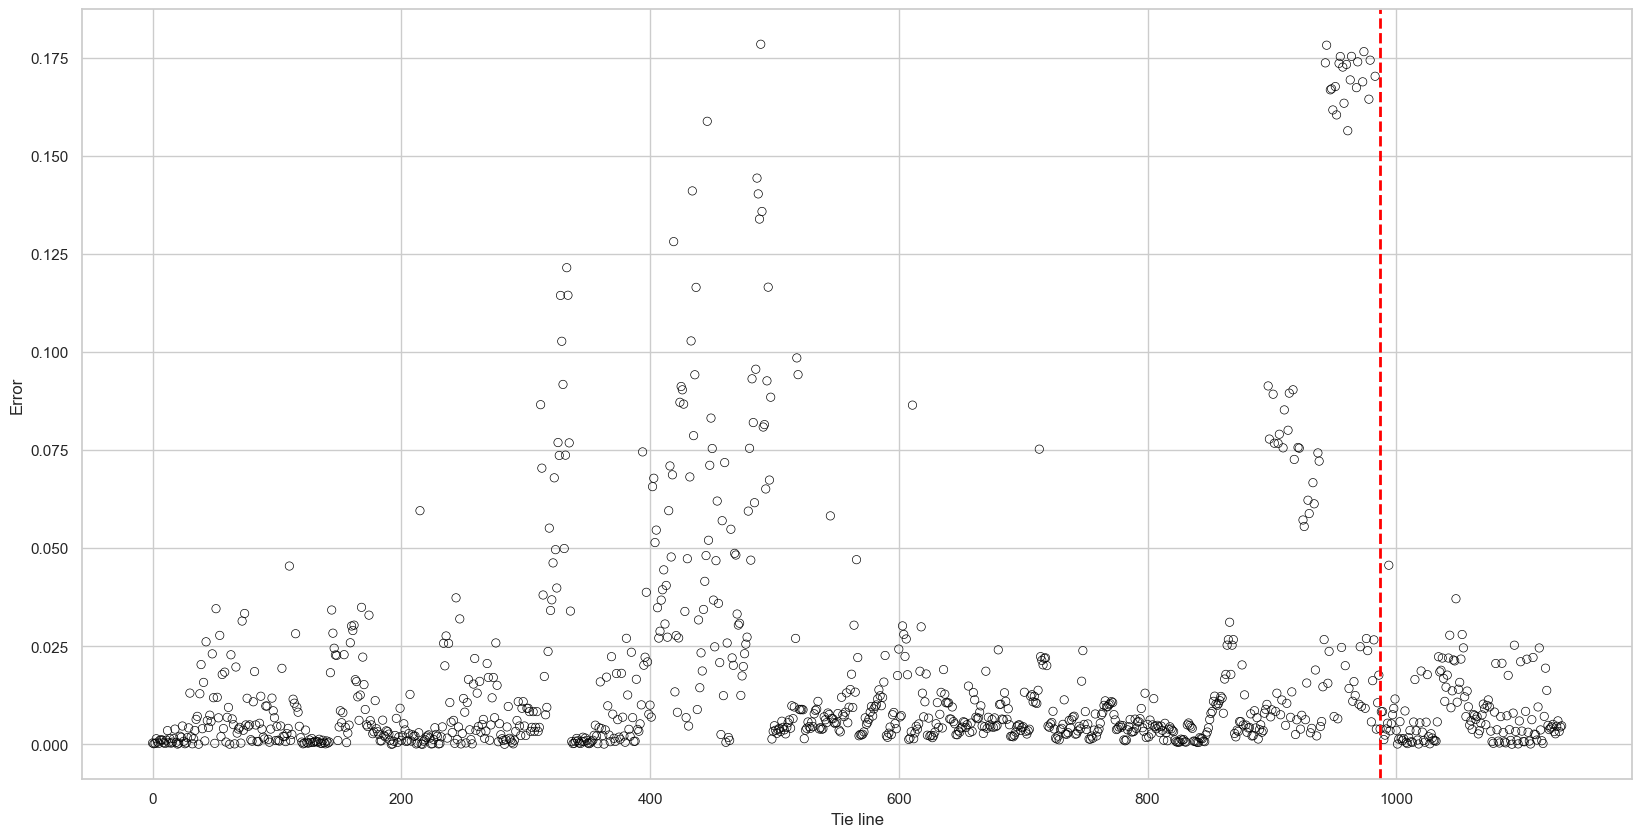

In [94]:
sns.set_theme(rc={'figure.figsize':(20,10)})
sns.set_style("whitegrid")
sns.scatterplot(x = range(exp_compositions_np.shape[0]), y =  np.sum((exp_compositions_np - calculated_data_np)**2, 1)/exp_compositions.shape[0]*100, 
                facecolor = "none", edgecolor = "black").set(xlabel = "Tie line", ylabel="Error")
plt.axvline(x=987, color='red', linestyle='--', linewidth=2)
plt.show()

In [95]:
non_zero_mask = np.any(calculated_data_np != 0, axis=1) & np.any(exp_compositions_np != 0, axis=1)
calculated_data_np = calculated_data_np[non_zero_mask]
exp_compositions_np = exp_compositions_np[non_zero_mask]

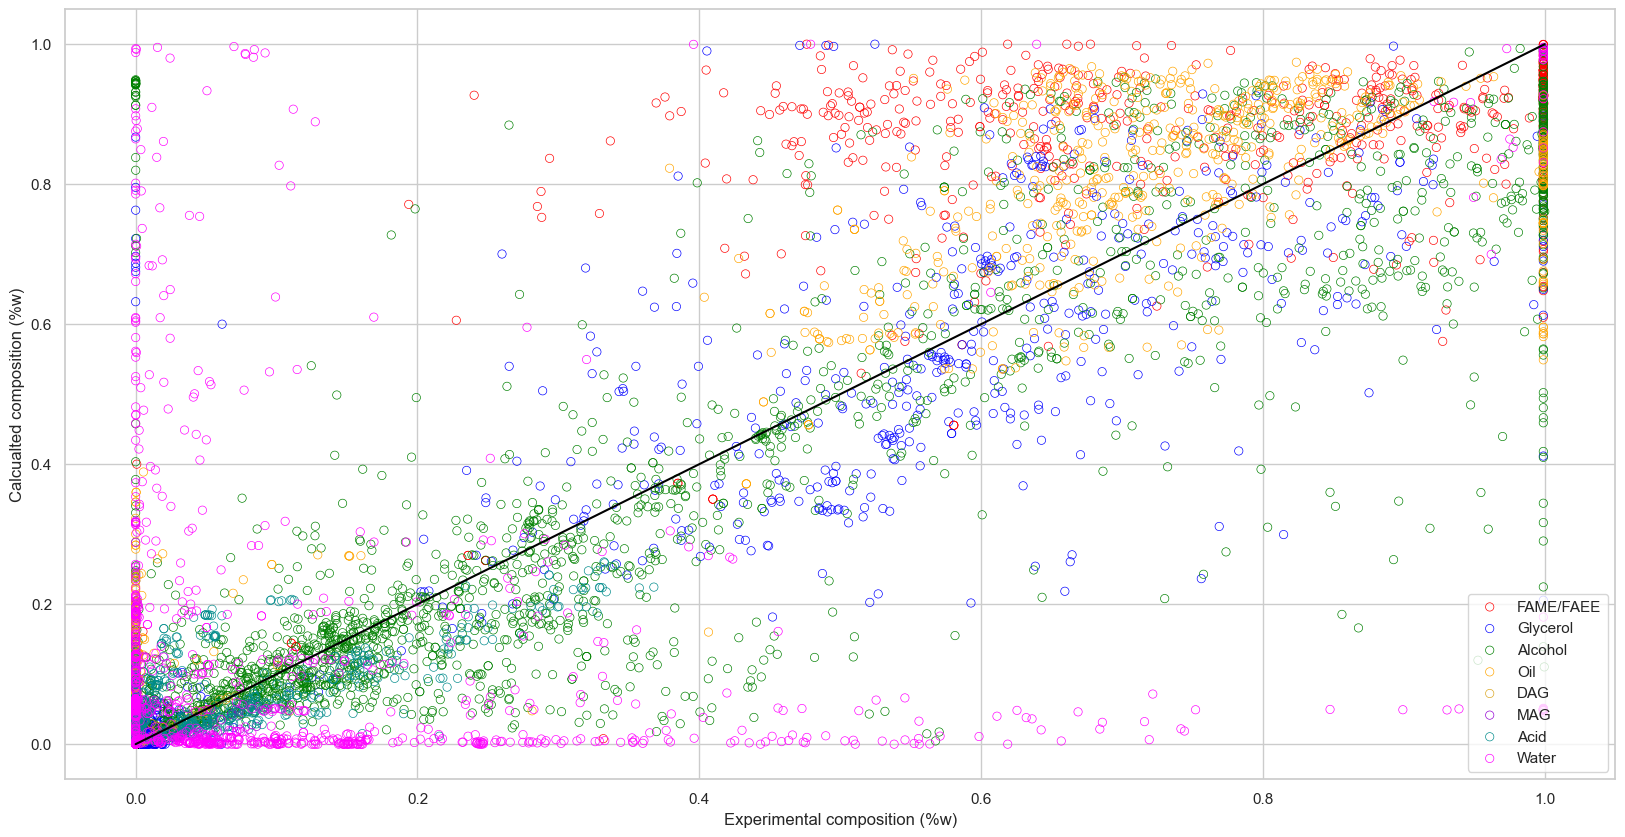

In [96]:
sns.lineplot(x = [0,1], y=[0,1], color = "black")
sns.scatterplot(x = calculated_data_np[:, 0], y = exp_compositions_np[:, 0], facecolor = "none", edgecolor = "red", label = "FAME/FAEE")
sns.scatterplot(x = calculated_data_np[:, 8], y = exp_compositions_np[:, 8], facecolor = "none", edgecolor = "red")

sns.scatterplot(x = calculated_data_np[:, 1], y = exp_compositions_np[:, 1], facecolor = "none", edgecolor = "blue", label = "Glycerol")
sns.scatterplot(x = calculated_data_np[:, 9], y = exp_compositions_np[:, 9], facecolor = "none", edgecolor = "blue")

sns.scatterplot(x = calculated_data_np[:, 2], y = exp_compositions_np[:, 2], facecolor = "none", edgecolor = "green", label = "Alcohol")
sns.scatterplot(x = calculated_data_np[:, 10], y = exp_compositions_np[:, 10], facecolor = "none", edgecolor = "green")

sns.scatterplot(x = calculated_data_np[:, 3], y = exp_compositions_np[:, 3], facecolor = "none", edgecolor = "orange", label = "Oil")
sns.scatterplot(x = calculated_data_np[:, 11], y = exp_compositions_np[:, 11], facecolor = "none", edgecolor = "orange")

sns.scatterplot(x = calculated_data_np[:, 4], y = exp_compositions_np[:, 4], facecolor = "none", edgecolor = "goldenrod", label = "DAG")
sns.scatterplot(x = calculated_data_np[:, 12], y = exp_compositions_np[:, 12], facecolor = "none", edgecolor = "goldenrod")

sns.scatterplot(x = calculated_data_np[:, 5], y = exp_compositions_np[:, 5], facecolor = "none", edgecolor = "darkviolet", label = "MAG")
sns.scatterplot(x = calculated_data_np[:, 13], y = exp_compositions_np[:, 13], facecolor = "none", edgecolor = "darkviolet")

sns.scatterplot(x = calculated_data_np[:, 6], y = exp_compositions_np[:, 6], facecolor = "none", edgecolor = "darkcyan", label = "Acid")
sns.scatterplot(x = calculated_data_np[:, 14], y = exp_compositions_np[:, 14], facecolor = "none", edgecolor = "darkcyan")

sns.scatterplot(x = calculated_data_np[:, 7], y = exp_compositions_np[:, 7], facecolor = "none", edgecolor = "magenta", label = "Water")
sns.scatterplot(x = calculated_data_np[:, 15], y = exp_compositions_np[:, 15], facecolor = "none", edgecolor = "magenta").set(xlabel = "Experimental composition (%w)", ylabel = "Calcualted composition (%w)")
plt.show()

#### Evaluation of new params V1

In [10]:
calculated_data = pl.read_excel("UDortmund_Results.xlsx", engine="calamine")

In [11]:
calculated_data_np = calculated_data.to_numpy()

In [12]:
total_error = np.sum((exp_compositions_np - calculated_data_np)**2)/exp_compositions.shape[0]*100
print("El error total es: ", total_error)

El error total es:  17.07625905051554


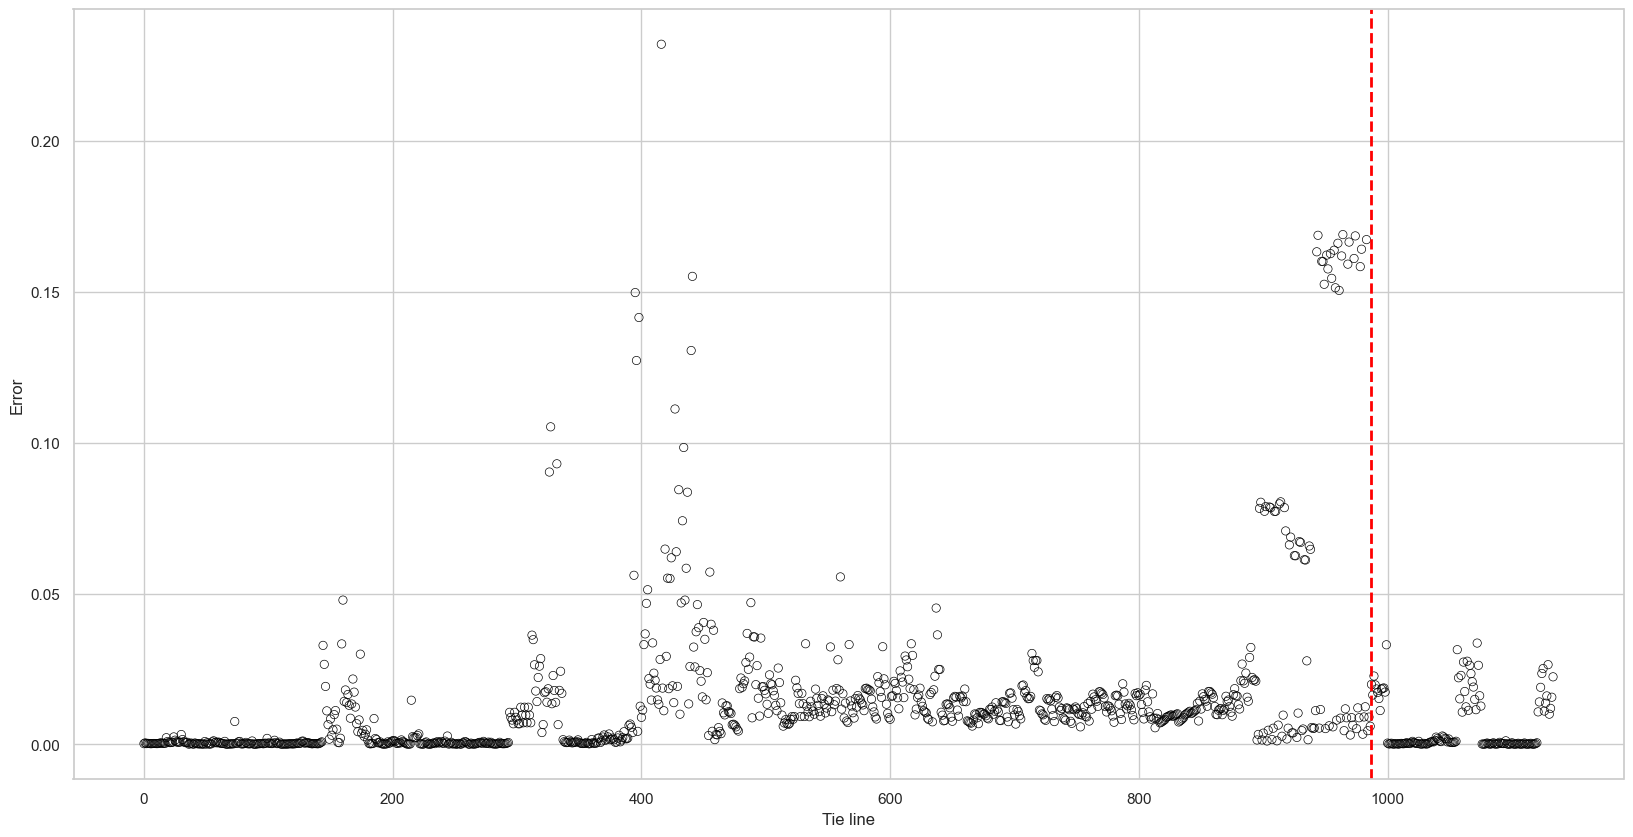

In [13]:
sns.set_theme(rc={'figure.figsize':(20,10)})
sns.set_style("whitegrid")
sns.scatterplot(x = range(exp_compositions_np.shape[0]), y =  np.sum((exp_compositions_np - calculated_data_np)**2, 1)/exp_compositions.shape[0]*100, 
                facecolor = "none", edgecolor = "black").set(xlabel = "Tie line", ylabel="Error")
plt.axvline(x=987, color='red', linestyle='--', linewidth=2)
plt.show()

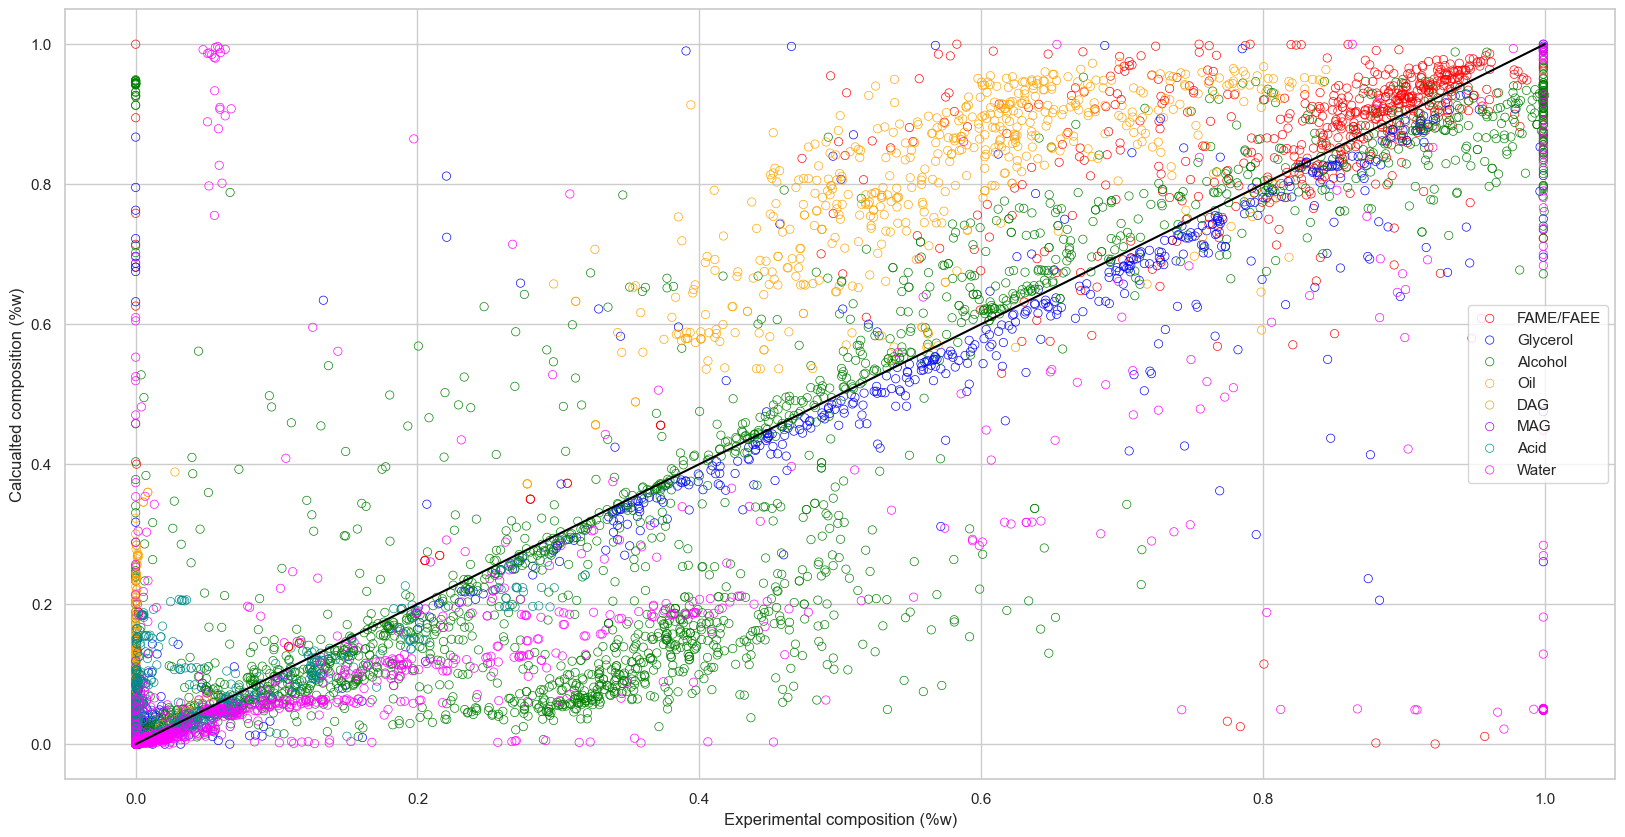

In [15]:
sns.lineplot(x = [0,1], y=[0,1], color = "black")
sns.scatterplot(x = calculated_data_np[:, 0], y = exp_compositions_np[:, 0], facecolor = "none", edgecolor = "red", label = "FAME/FAEE")
sns.scatterplot(x = calculated_data_np[:, 8], y = exp_compositions_np[:, 8], facecolor = "none", edgecolor = "red")

sns.scatterplot(x = calculated_data_np[:, 1], y = exp_compositions_np[:, 1], facecolor = "none", edgecolor = "blue", label = "Glycerol")
sns.scatterplot(x = calculated_data_np[:, 9], y = exp_compositions_np[:, 9], facecolor = "none", edgecolor = "blue")

sns.scatterplot(x = calculated_data_np[:, 2], y = exp_compositions_np[:, 2], facecolor = "none", edgecolor = "green", label = "Alcohol")
sns.scatterplot(x = calculated_data_np[:, 10], y = exp_compositions_np[:, 10], facecolor = "none", edgecolor = "green")

sns.scatterplot(x = calculated_data_np[:, 3], y = exp_compositions_np[:, 3], facecolor = "none", edgecolor = "orange", label = "Oil")
sns.scatterplot(x = calculated_data_np[:, 11], y = exp_compositions_np[:, 11], facecolor = "none", edgecolor = "orange")

sns.scatterplot(x = calculated_data_np[:, 4], y = exp_compositions_np[:, 4], facecolor = "none", edgecolor = "goldenrod", label = "DAG")
sns.scatterplot(x = calculated_data_np[:, 12], y = exp_compositions_np[:, 12], facecolor = "none", edgecolor = "goldenrod")

sns.scatterplot(x = calculated_data_np[:, 5], y = exp_compositions_np[:, 5], facecolor = "none", edgecolor = "darkviolet", label = "MAG")
sns.scatterplot(x = calculated_data_np[:, 13], y = exp_compositions_np[:, 13], facecolor = "none", edgecolor = "darkviolet")

sns.scatterplot(x = calculated_data_np[:, 6], y = exp_compositions_np[:, 6], facecolor = "none", edgecolor = "darkcyan", label = "Acid")
sns.scatterplot(x = calculated_data_np[:, 14], y = exp_compositions_np[:, 14], facecolor = "none", edgecolor = "darkcyan")

sns.scatterplot(x = calculated_data_np[:, 7], y = exp_compositions_np[:, 7], facecolor = "none", edgecolor = "magenta", label = "Water")
sns.scatterplot(x = calculated_data_np[:, 15], y = exp_compositions_np[:, 15], facecolor = "none", edgecolor = "magenta").set(xlabel = "Experimental composition (%w)", ylabel = "Calcualted composition (%w)")
plt.show()

#### Evaluation of new params V2

In [16]:
calculated_data = pl.read_excel("UDortmund_Results_V2.xlsx", engine="calamine")

In [17]:
calculated_data_np = calculated_data.to_numpy()

In [18]:
total_error = np.sum((exp_compositions_np - calculated_data_np)**2)/exp_compositions.shape[0]*100
print("El error total es: ", total_error)

El error total es:  16.517546728370245


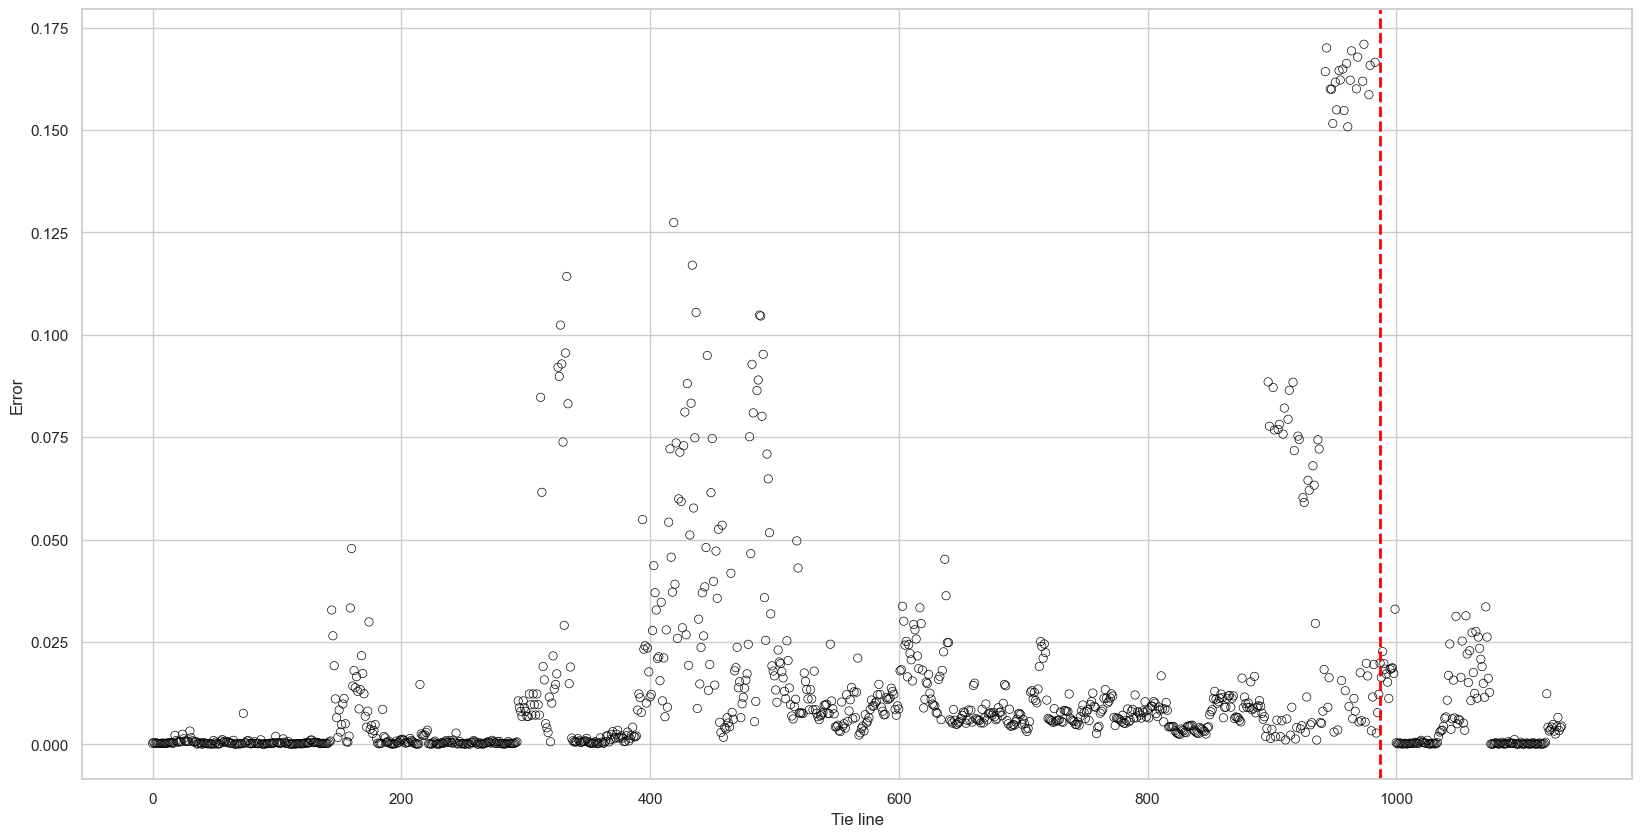

In [19]:
sns.set_theme(rc={'figure.figsize':(20,10)})
sns.set_style("whitegrid")
sns.scatterplot(x = range(exp_compositions_np.shape[0]), y =  np.sum((exp_compositions_np - calculated_data_np)**2, 1)/exp_compositions.shape[0]*100, 
                facecolor = "none", edgecolor = "black").set(xlabel = "Tie line", ylabel="Error")
plt.axvline(x=987, color='red', linestyle='--', linewidth=2)
plt.show()

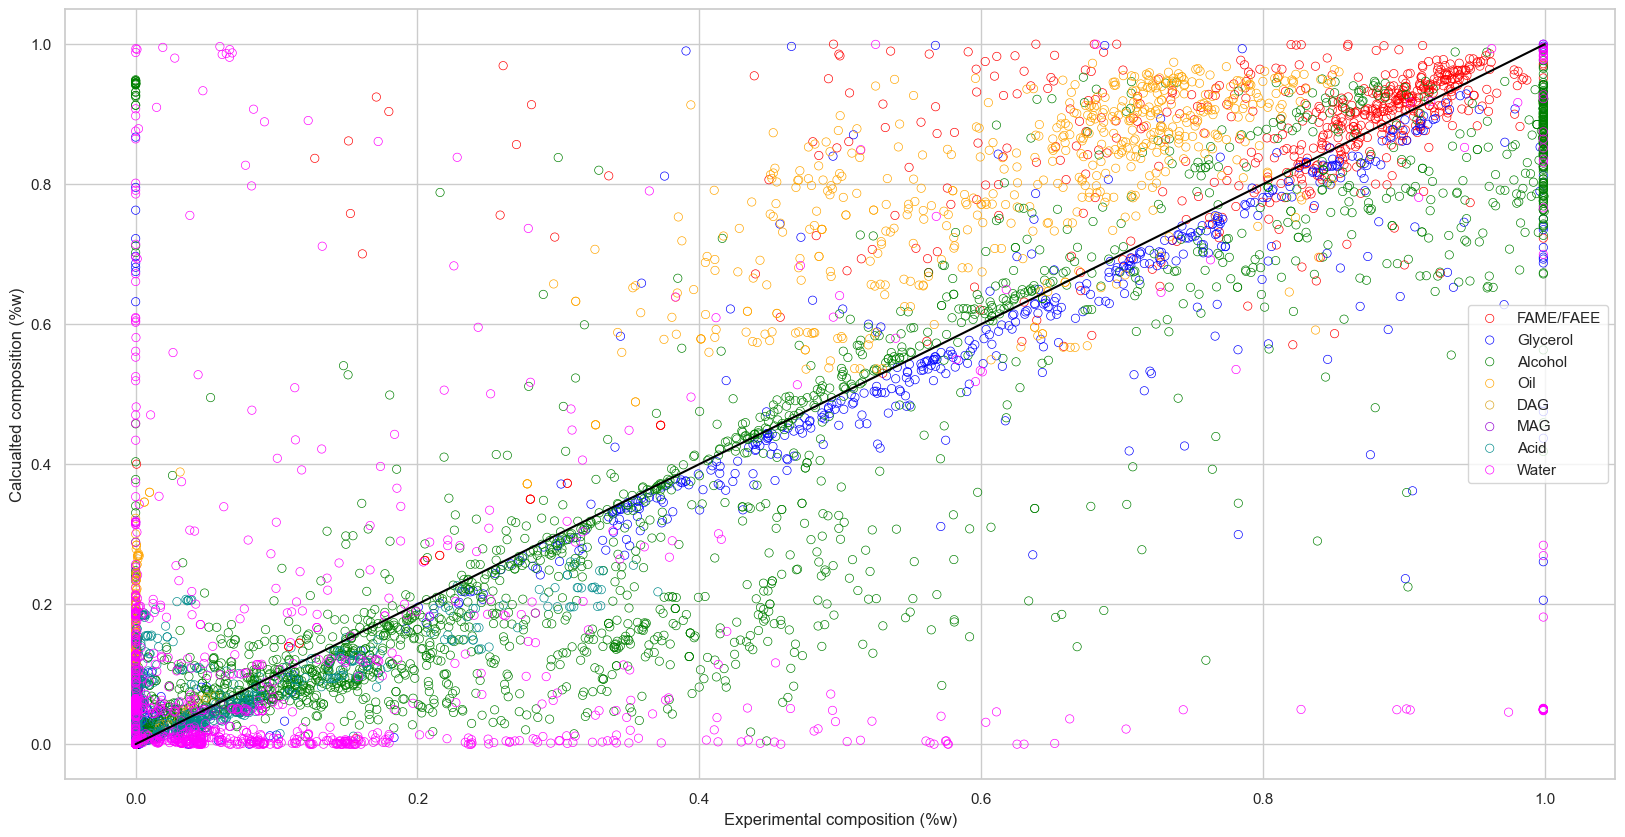

In [20]:
sns.lineplot(x = [0,1], y=[0,1], color = "black")
sns.scatterplot(x = calculated_data_np[:, 0], y = exp_compositions_np[:, 0], facecolor = "none", edgecolor = "red", label = "FAME/FAEE")
sns.scatterplot(x = calculated_data_np[:, 8], y = exp_compositions_np[:, 8], facecolor = "none", edgecolor = "red")

sns.scatterplot(x = calculated_data_np[:, 1], y = exp_compositions_np[:, 1], facecolor = "none", edgecolor = "blue", label = "Glycerol")
sns.scatterplot(x = calculated_data_np[:, 9], y = exp_compositions_np[:, 9], facecolor = "none", edgecolor = "blue")

sns.scatterplot(x = calculated_data_np[:, 2], y = exp_compositions_np[:, 2], facecolor = "none", edgecolor = "green", label = "Alcohol")
sns.scatterplot(x = calculated_data_np[:, 10], y = exp_compositions_np[:, 10], facecolor = "none", edgecolor = "green")

sns.scatterplot(x = calculated_data_np[:, 3], y = exp_compositions_np[:, 3], facecolor = "none", edgecolor = "orange", label = "Oil")
sns.scatterplot(x = calculated_data_np[:, 11], y = exp_compositions_np[:, 11], facecolor = "none", edgecolor = "orange")

sns.scatterplot(x = calculated_data_np[:, 4], y = exp_compositions_np[:, 4], facecolor = "none", edgecolor = "goldenrod", label = "DAG")
sns.scatterplot(x = calculated_data_np[:, 12], y = exp_compositions_np[:, 12], facecolor = "none", edgecolor = "goldenrod")

sns.scatterplot(x = calculated_data_np[:, 5], y = exp_compositions_np[:, 5], facecolor = "none", edgecolor = "darkviolet", label = "MAG")
sns.scatterplot(x = calculated_data_np[:, 13], y = exp_compositions_np[:, 13], facecolor = "none", edgecolor = "darkviolet")

sns.scatterplot(x = calculated_data_np[:, 6], y = exp_compositions_np[:, 6], facecolor = "none", edgecolor = "darkcyan", label = "Acid")
sns.scatterplot(x = calculated_data_np[:, 14], y = exp_compositions_np[:, 14], facecolor = "none", edgecolor = "darkcyan")

sns.scatterplot(x = calculated_data_np[:, 7], y = exp_compositions_np[:, 7], facecolor = "none", edgecolor = "magenta", label = "Water")
sns.scatterplot(x = calculated_data_np[:, 15], y = exp_compositions_np[:, 15], facecolor = "none", edgecolor = "magenta").set(xlabel = "Experimental composition (%w)", ylabel = "Calcualted composition (%w)")
plt.show()